ALDANA: hace Ctrl+Shift+P → Developer: Reload Window. Sino no anda.

##### Librerías

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

## Dataset

In [2]:
# Lectura de dataset
df = pd.read_csv('weatherAUS_2026C2.csv')
df.head()

,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,...,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,...,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,...,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,...,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,...,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2


### Descripcion

In [3]:
# Medidas del dataset (filas, columnas)
df.shape

(145412, 25)

In [4]:
# Medidas estadísticas principales del dataset
df.describe()

,Unnamed: 0,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainfallTomorrow
count,145412.000000,143928.000000,144159.000000,142152.000000,82658.000000,75616.000000,135159.000000,143645.000000,142351.000000,142759.000000,140907.000000,130351.000000,130388.000000,89542.000000,86076.000000,143646.000000,141805.000000,142153.000000
mean,72728.184393,12.196528,23.223064,2.361516,5.468616,7.611241,40.036668,14.067277,18.661899,68.861521,51.532206,1017.647237,1015.255080,4.447287,4.509770,16.991981,21.683360,2.361242
std,41990.722236,6.417956,7.135927,8.479338,4.193871,3.785612,13.648259,8.936768,8.865457,19.062866,20.844414,7.113833,7.044507,2.887161,2.720306,6.509191,6.953072,8.479084
min,0.000000,-9.700000,-5.100000,0.000000,0.000000,0.000000,6.000000,0.000000,0.000000,0.000000,0.000000,980.300000,977.400000,0.000000,0.000000,-8.000000,-5.800000,0.000000
25%,36362.750000,7.600000,17.900000,0.000000,2.600000,4.800000,31.000000,7.000000,12.000000,57.000000,36.600000,1012.900000,1010.400000,1.000000,2.000000,12.300000,16.600000,0.000000
50%,72727.500000,12.000000,22.600000,0.000000,4.800000,8.400000,38.000000,13.000000,18.000000,69.900000,52.000000,1017.600000,1015.200000,5.000000,5.000000,16.700000,21.100000,0.000000
75%,109093.250000,16.900000,28.200000,0.800000,7.400000,10.600000,48.000000,19.000000,24.000000,83.100000,65.700000,1022.400000,1020.000000,7.000000,7.000000,21.600000,26.400000,0.800000
max,145458.000000,34.100000,49.100000,371.000000,145.000000,14.500000,135.000000,130.000000,86.000000,100.000000,100.000000,1041.200000,1039.800000,9.000000,9.000000,39.800000,47.000000,371.000000


In [5]:
# Tipos de datos, valores no nulos, nulos y porcentaje de nulos.

# Como df.info() no muestra todas las columnas ya que sobrepasa el límite de filas, 
# se utiliza pd.option_context para mostrar todas las columnas y sus tipos de datos.

with pd.option_context('display.max_rows', None):
    display(pd.DataFrame({
        'no_nulos': df.count(),
        'nulos': df.isna().sum(),
        'dtype': df.dtypes,
        '%_nulos': (df.isna().mean() * 100).round(2)}))

,no_nulos,nulos,dtype,%_nulos
Unnamed: 0,145412,0,int64,0.00
Date,145412,0,str,0.00
Location,145412,0,str,0.00
MinTemp,143928,1484,float64,1.02
MaxTemp,144159,1253,float64,0.86
Rainfall,142152,3260,float64,2.24
Evaporation,82658,62754,float64,43.16
Sunshine,75616,69796,float64,48.00
WindGustDir,135096,10316,str,7.09
WindGustSpeed,135159,10253,float64,7.05


Notamos de este primer vistazo que las siguientes columnas tienen menos de un 5% faltante:
- Unnamed (correspondiente al índice)
- Date
- Location
- MinTemp
- MaxTemp
- Rainfall
- WindDir3pm
- WindSpeed9am
- WindSpeed3pm
- Humidity9am
- Humidity3pm
- Temp9am
- Temp3pm
- RainToday
- RainTomorrow
- RainfallTomorrow

Las siguientes columnas tienen un faltante de aproximadamente 10%:
- WindGustDir
- WindGustSpeed
- WindDir9am
- Pressure9am
- Pressure3pm

Y por ultimo estas variables poseen una falta de hasta un 50%:
- Evaporation
- Sunshine
- Cloud9am
- Cloud3pm

#### Gráficos descriptivos
##### Boxplots e Histogramas

C:\Users\aldys\AppData\Local\Temp\ipykernel_24008\200963821.py:36: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


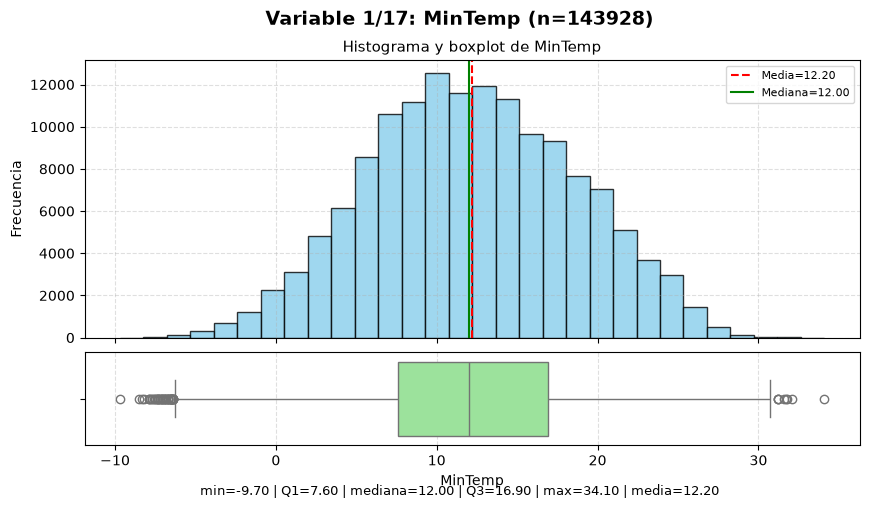

C:\Users\aldys\AppData\Local\Temp\ipykernel_24008\200963821.py:36: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


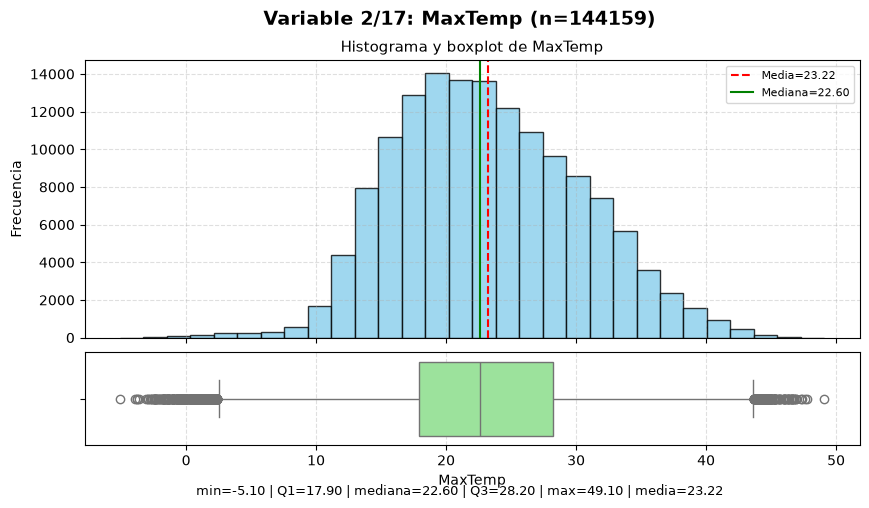

C:\Users\aldys\AppData\Local\Temp\ipykernel_24008\200963821.py:36: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


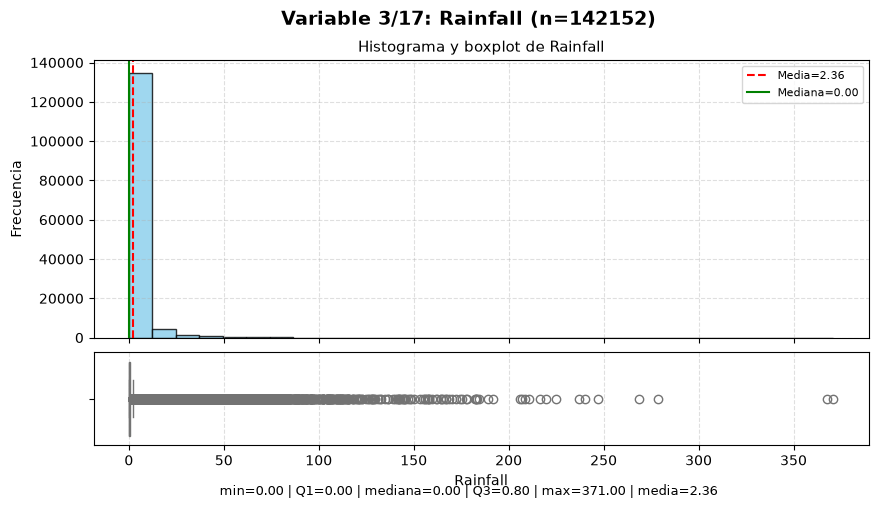

C:\Users\aldys\AppData\Local\Temp\ipykernel_24008\200963821.py:36: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


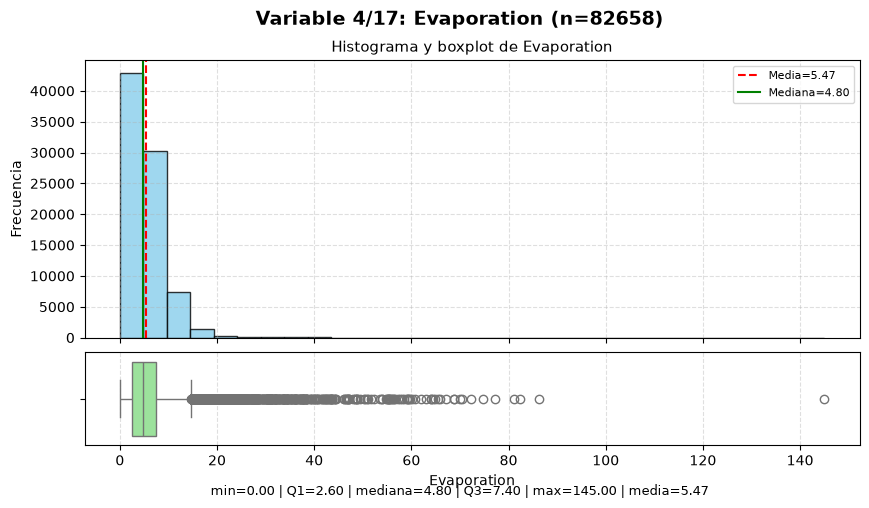

C:\Users\aldys\AppData\Local\Temp\ipykernel_24008\200963821.py:36: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


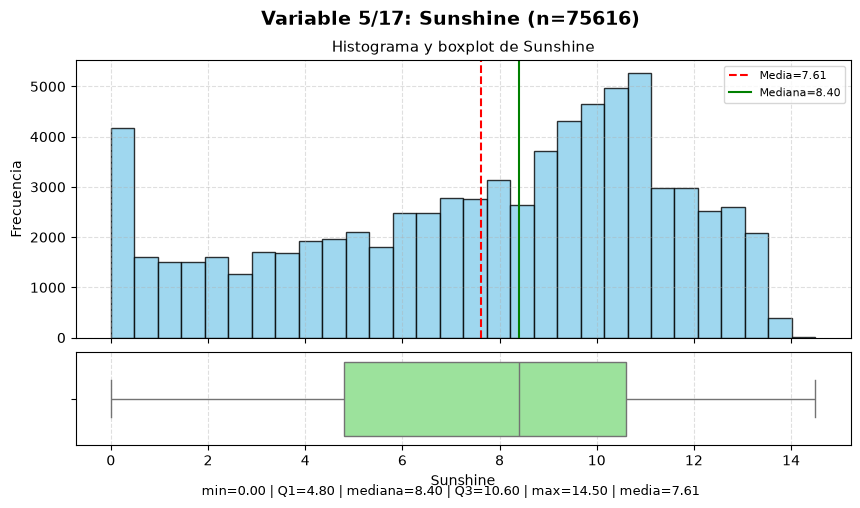

C:\Users\aldys\AppData\Local\Temp\ipykernel_24008\200963821.py:36: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


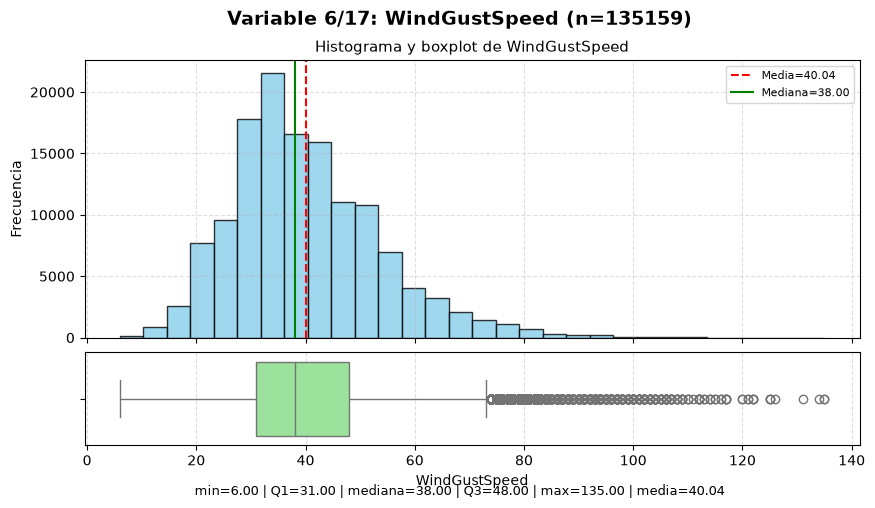

C:\Users\aldys\AppData\Local\Temp\ipykernel_24008\200963821.py:36: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


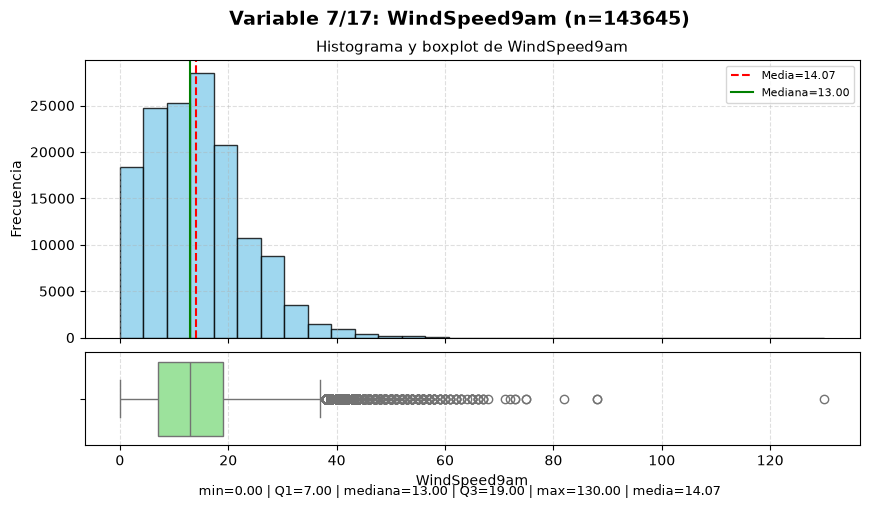

C:\Users\aldys\AppData\Local\Temp\ipykernel_24008\200963821.py:36: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


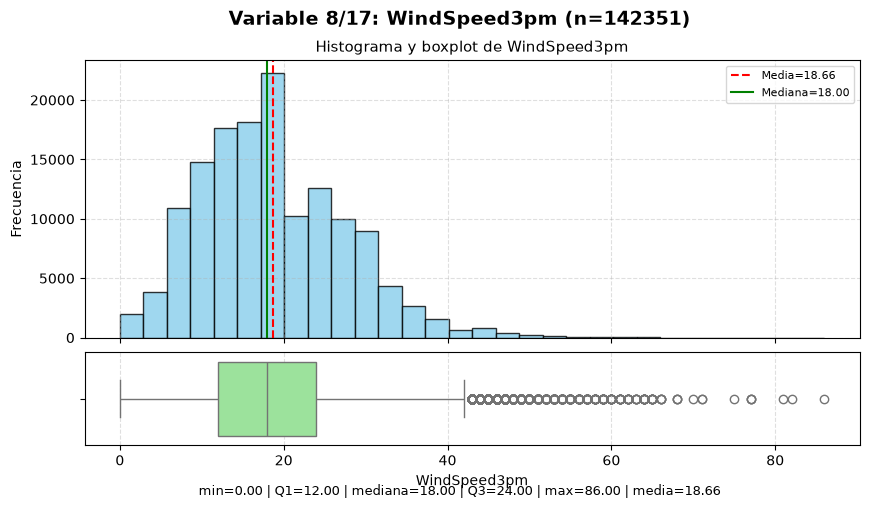

C:\Users\aldys\AppData\Local\Temp\ipykernel_24008\200963821.py:36: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


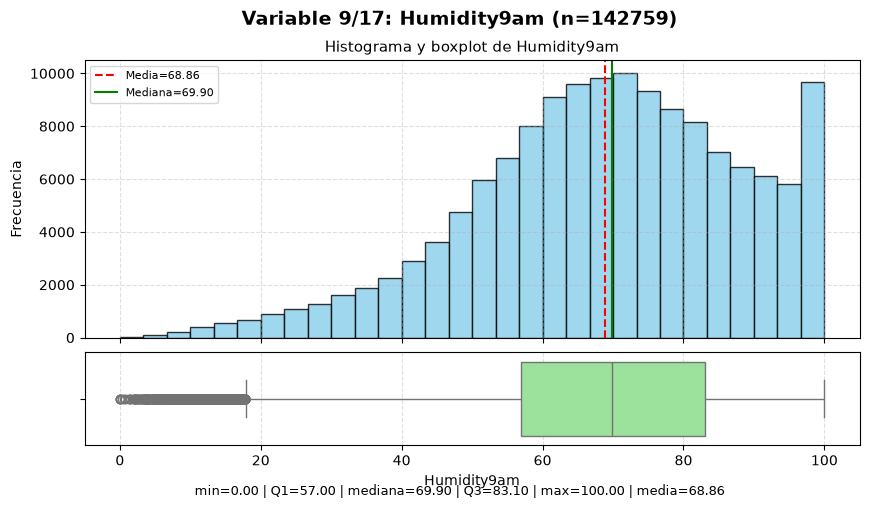

C:\Users\aldys\AppData\Local\Temp\ipykernel_24008\200963821.py:36: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


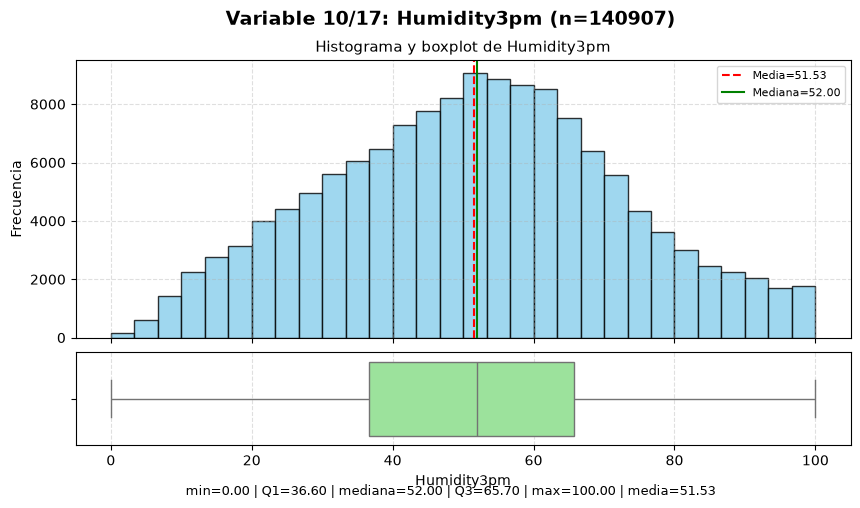

C:\Users\aldys\AppData\Local\Temp\ipykernel_24008\200963821.py:36: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


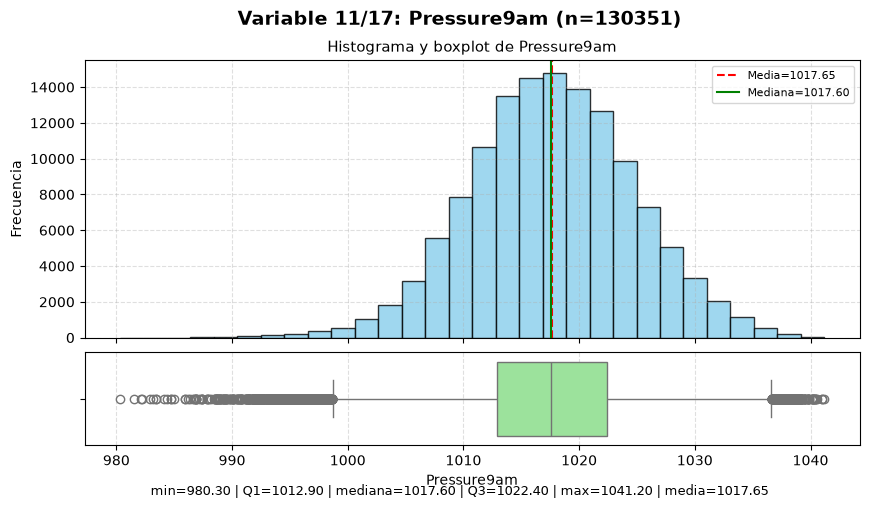

C:\Users\aldys\AppData\Local\Temp\ipykernel_24008\200963821.py:36: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


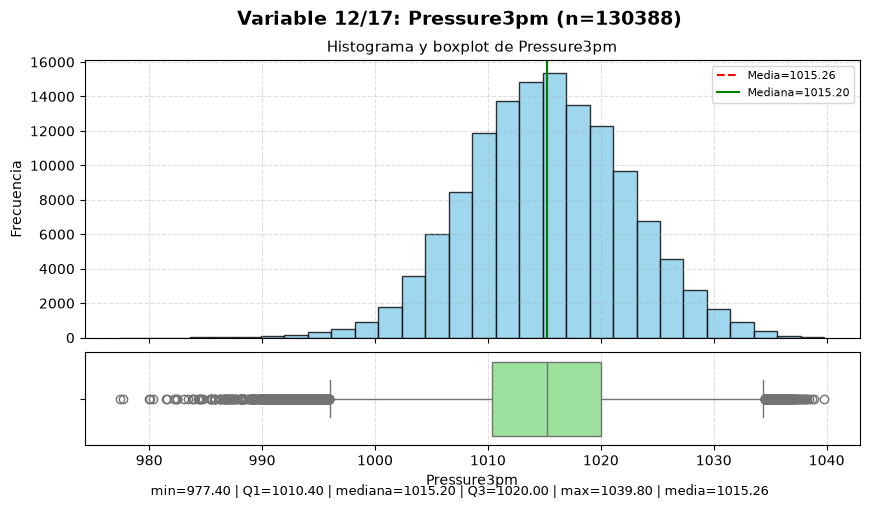

C:\Users\aldys\AppData\Local\Temp\ipykernel_24008\200963821.py:36: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


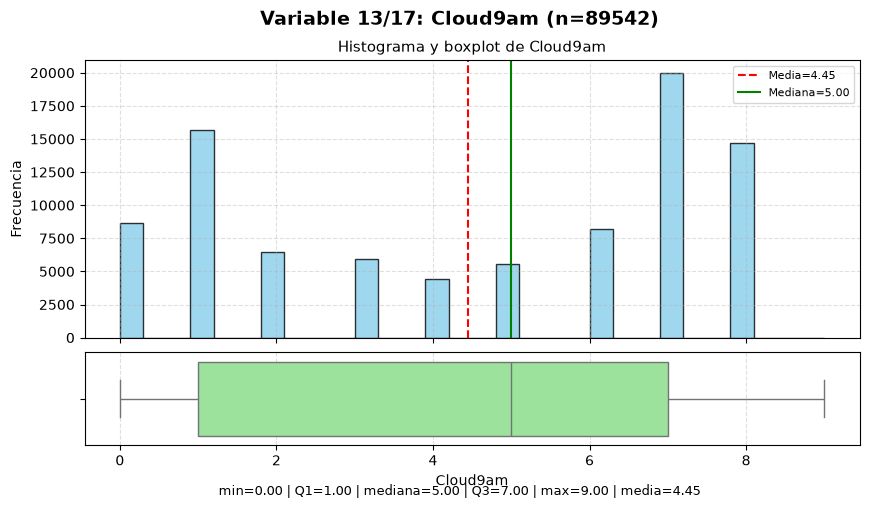

C:\Users\aldys\AppData\Local\Temp\ipykernel_24008\200963821.py:36: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


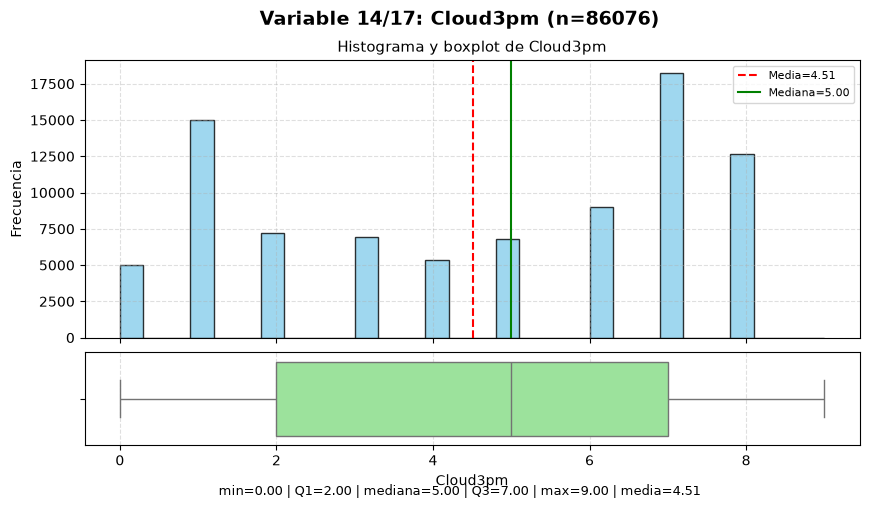

C:\Users\aldys\AppData\Local\Temp\ipykernel_24008\200963821.py:36: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


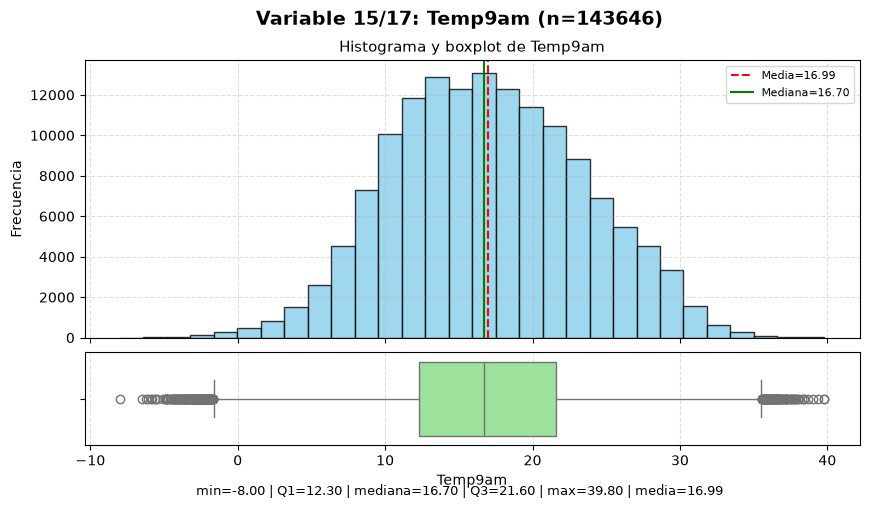

C:\Users\aldys\AppData\Local\Temp\ipykernel_24008\200963821.py:36: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


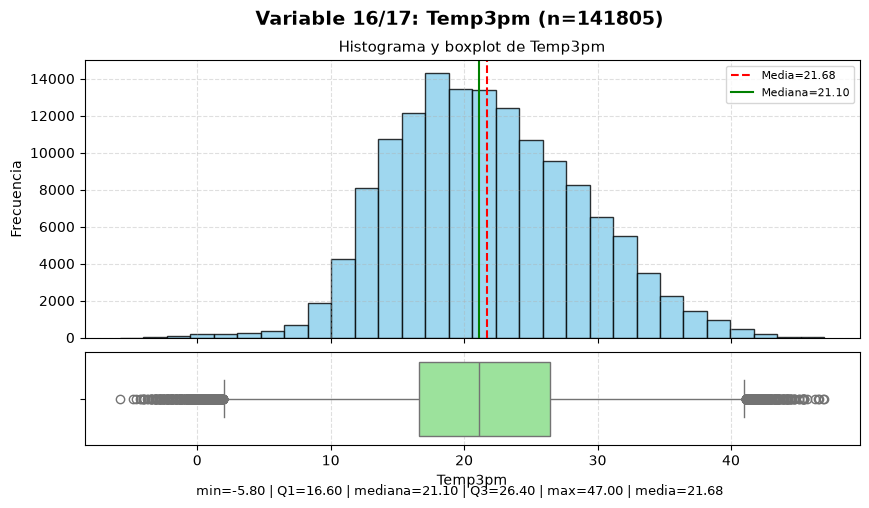

C:\Users\aldys\AppData\Local\Temp\ipykernel_24008\200963821.py:36: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 0.94])


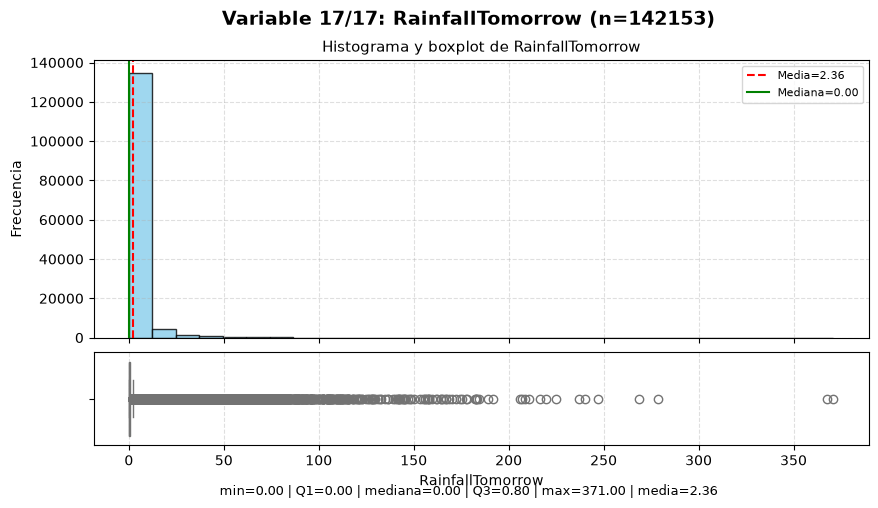

In [15]:
# Variables numéricas del dataset
variables_numericas = df.select_dtypes(include='number').columns

for i, col in enumerate(variables_numericas, start=1):
    datos = df[col].dropna()

    fig, (ax_hist, ax_box) = plt.subplots(
        2, 1, figsize=(10, 5), sharex=True,
        gridspec_kw={'height_ratios': [3, 1], 'hspace': 0.08}
    )
    fig.suptitle(f'Variable {i}/{len(variables_numericas)}: {col} (n={len(datos)})',
                 fontsize=14, fontweight='bold')

    # Histograma
    ax_hist.hist(datos, bins=30, color='skyblue', edgecolor='black', alpha=0.8)
    ax_hist.axvline(datos.mean(), color='red', linestyle='--', linewidth=1.5,
                    label=f'Media={datos.mean():.2f}')
    ax_hist.axvline(datos.median(), color='green', linestyle='-', linewidth=1.5,
                    label=f'Mediana={datos.median():.2f}')
    ax_hist.set_title(f'Histograma y boxplot de {col}', fontsize=11)
    ax_hist.set_ylabel('Frecuencia')
    ax_hist.grid(linestyle='--', alpha=0.4)
    ax_hist.legend(fontsize=8)

    # Boxplot
    sns.boxplot(x=datos, ax=ax_box, color='lightgreen')
    ax_box.set_xlabel(col)
    ax_box.grid(axis='x', linestyle='--', alpha=0.4)

    # Resumen numérico debajo de los gráficos
    resumen = (f'min={datos.min():.2f} | Q1={datos.quantile(0.25):.2f} | '
               f'mediana={datos.median():.2f} | Q3={datos.quantile(0.75):.2f} | '
               f'max={datos.max():.2f} | media={datos.mean():.2f}')
    fig.text(0.5, 0.01, resumen, ha='center', fontsize=9)

    plt.tight_layout(rect=[0, 0.04, 1, 0.94])
    plt.show()


###### Matrices de correlacion

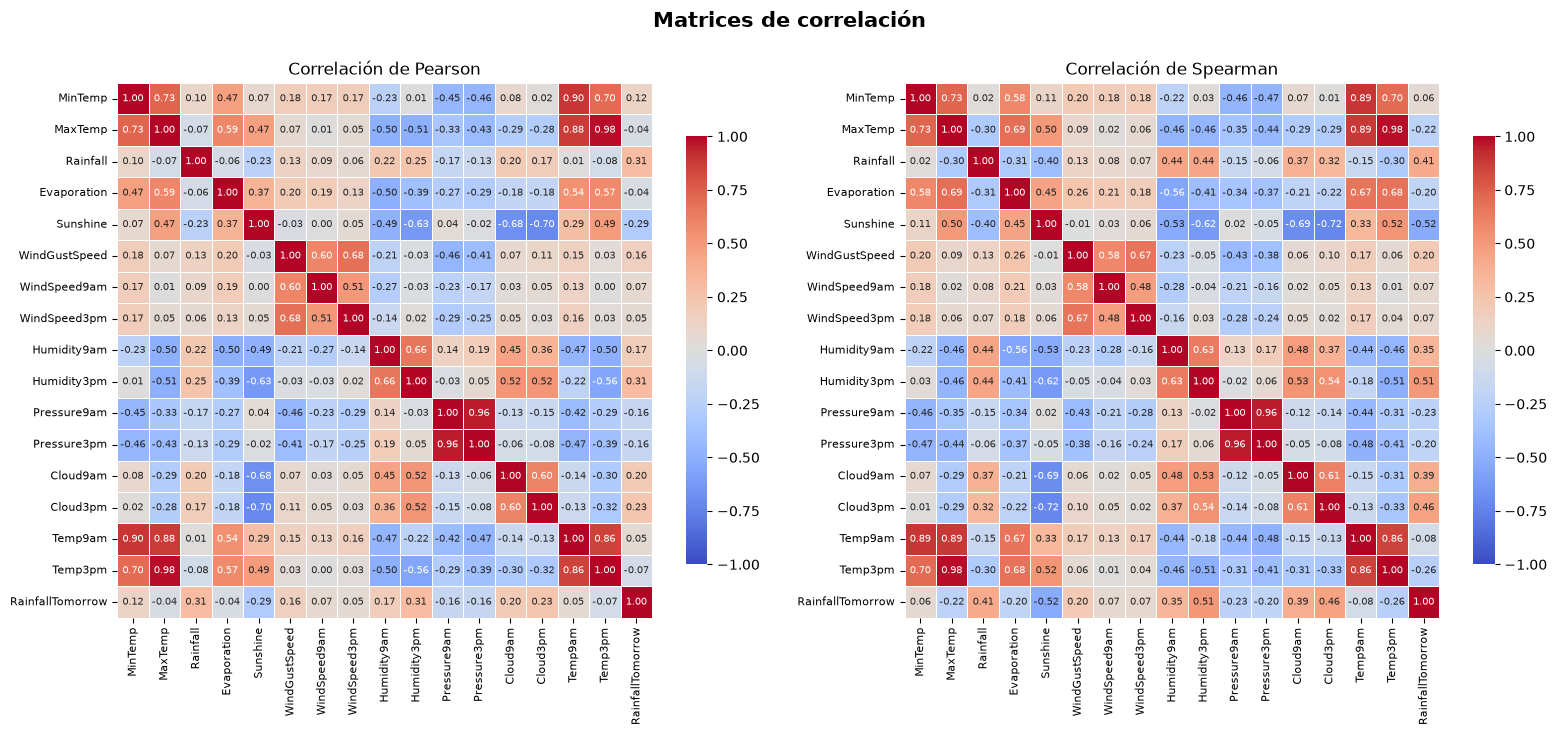

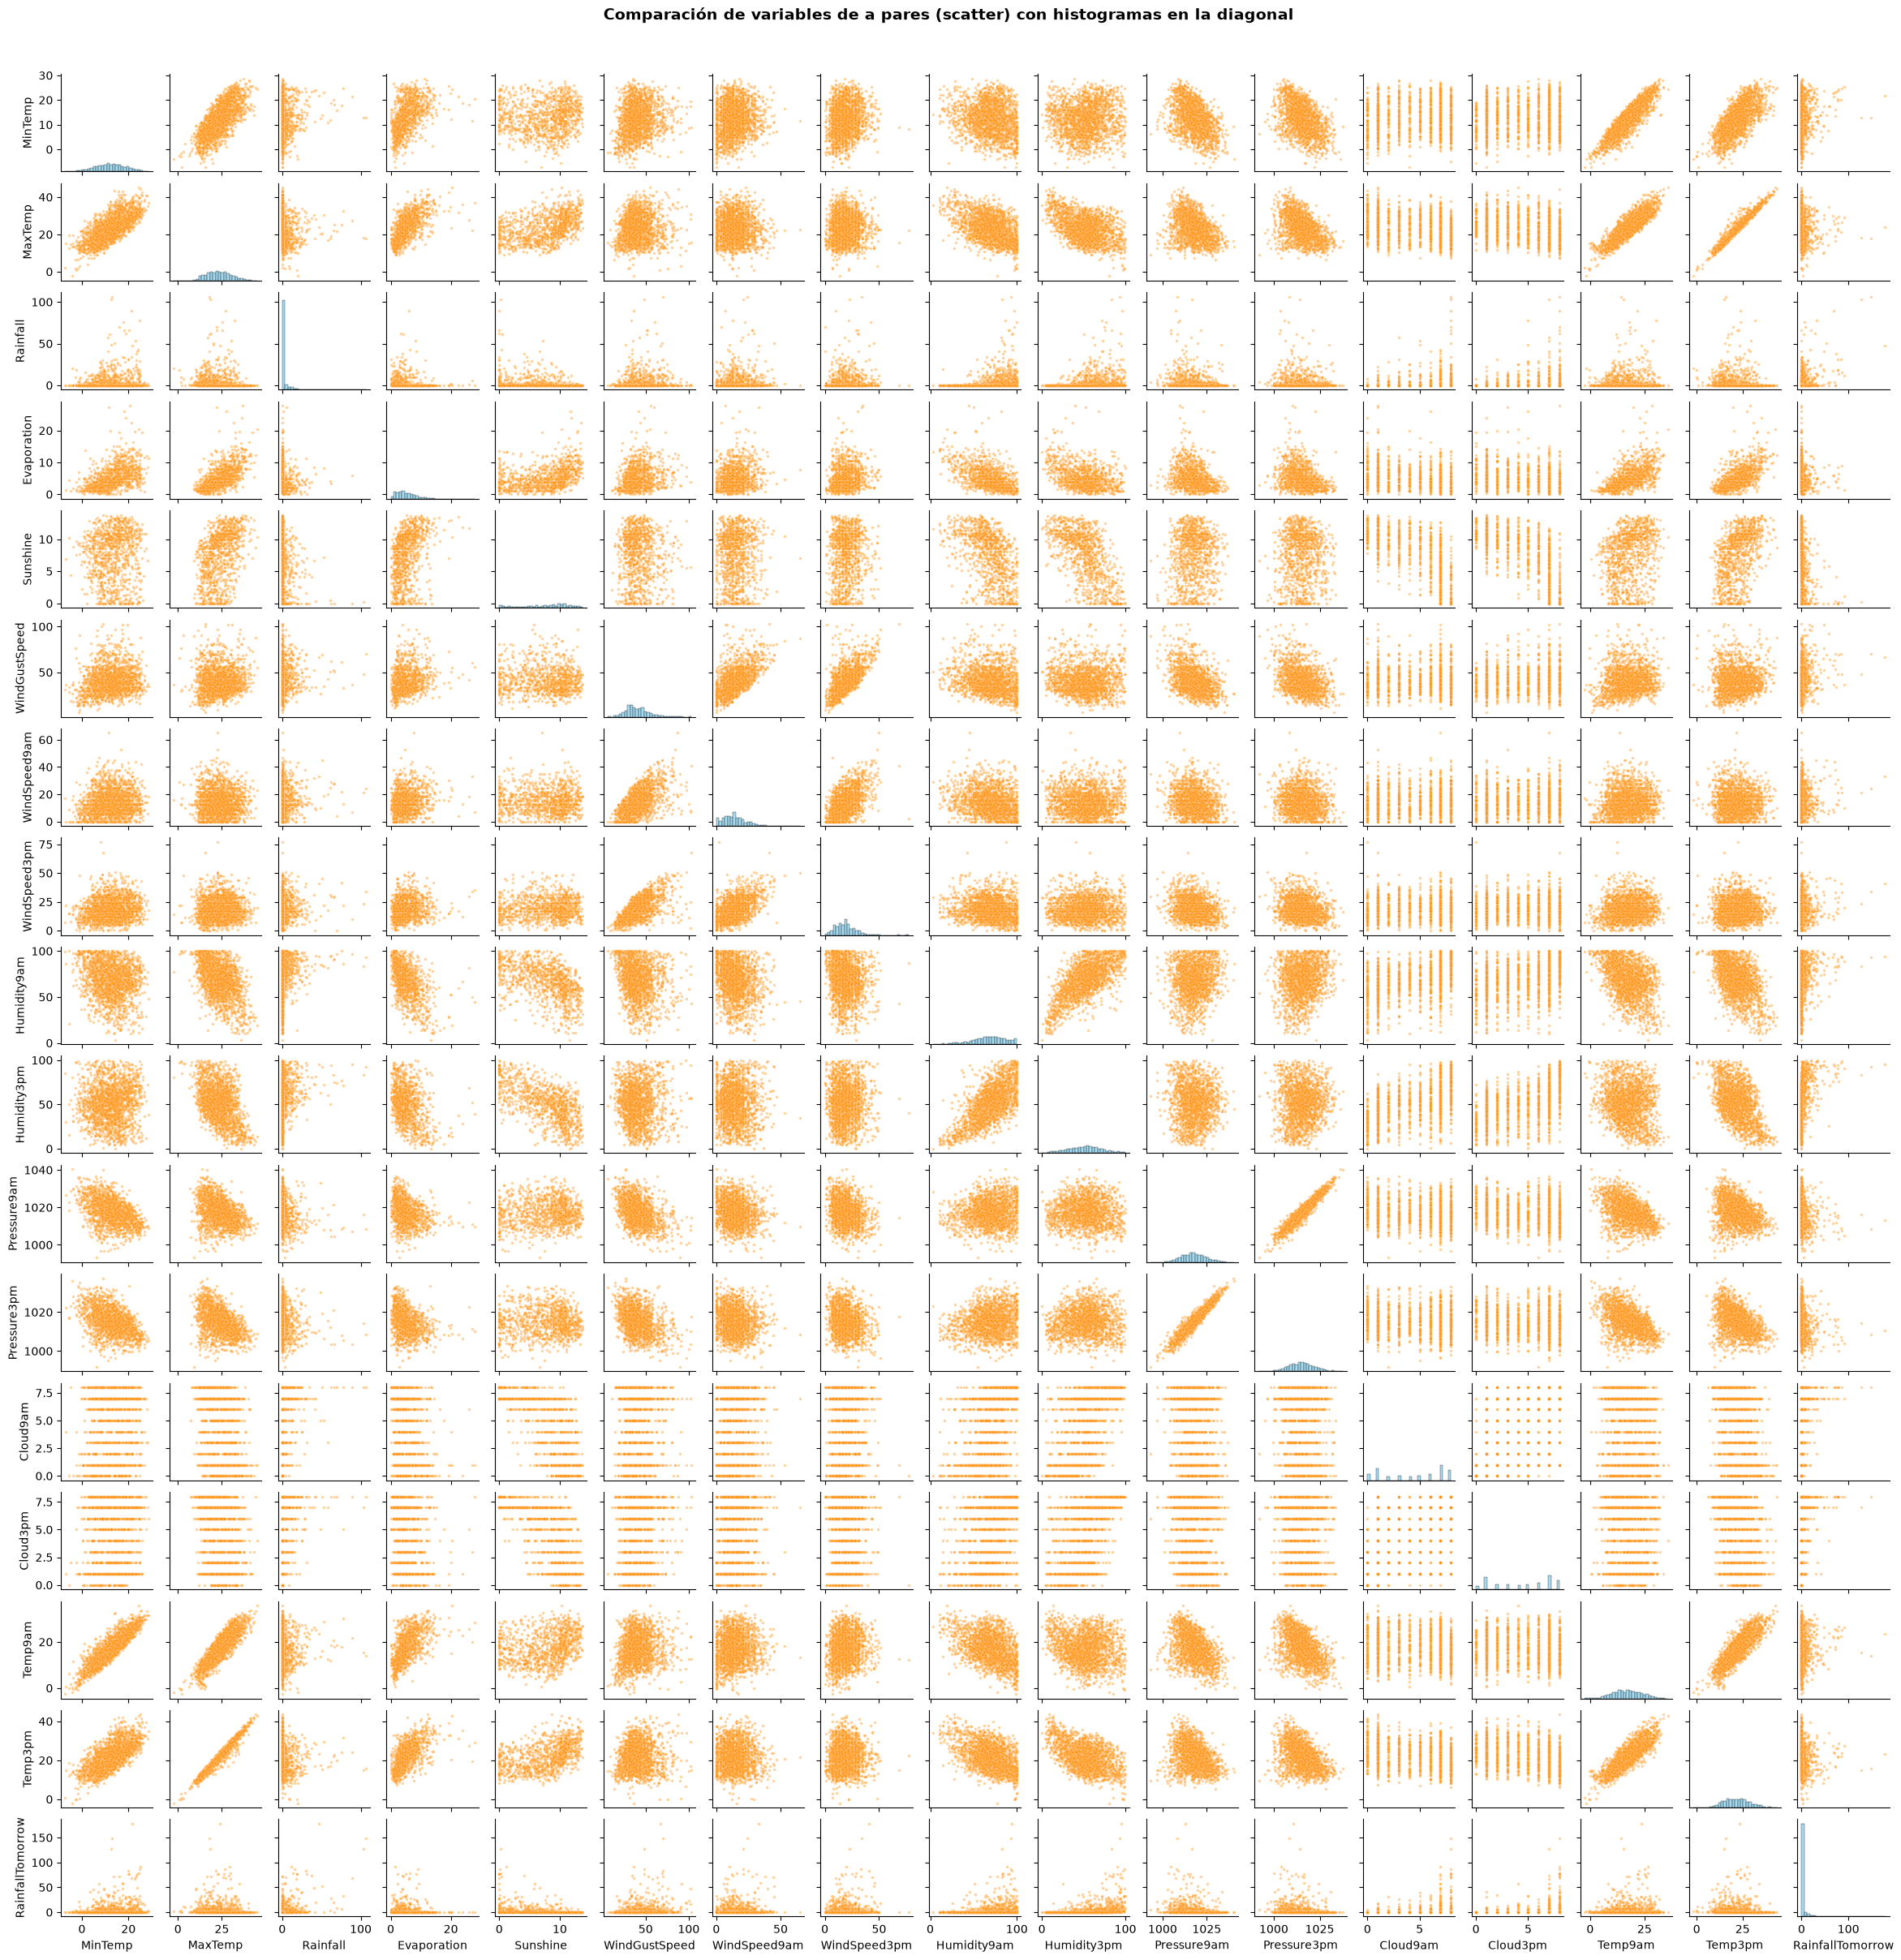

In [11]:
# Variables numéricas del dataset
df_num = df.select_dtypes(include='number')

# ---------- Matrices de correlación: Pearson y Spearman ----------
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('Matrices de correlación', fontsize=15, fontweight='bold')

for ax, metodo in zip(axes, ['pearson', 'spearman']):
    corr = df_num.corr(method=metodo)
    sns.heatmap(corr, ax=ax, annot=True, fmt='.2f', annot_kws={'size': 7},
                cmap='coolwarm', vmin=-1, vmax=1, square=True,
                linewidths=0.5, cbar_kws={'shrink': 0.8})
    ax.set_title(f'Correlación de {metodo.capitalize()}')
    ax.tick_params(labelsize=8)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# ---------- Gráfico de pares: scatters + histogramas en la diagonal ----------
# Se usa una muestra para que el gráfico sea legible y no tarde demasiado
muestra = df_num.sample(n=min(2000, len(df_num)), random_state=42)

g = sns.pairplot(muestra, diag_kind='hist',
                 plot_kws={'s': 6, 'alpha': 0.4, 'color': 'darkorange'},
                 diag_kws={'color': 'skyblue', 'edgecolor': 'black', 'bins': 30},
                 height=1.4)
g.figure.suptitle('Comparación de variables de a pares (scatter) con histogramas en la diagonal',
                  y=1.02, fontsize=14, fontweight='bold')
plt.show()

In [13]:
##### Histogramas

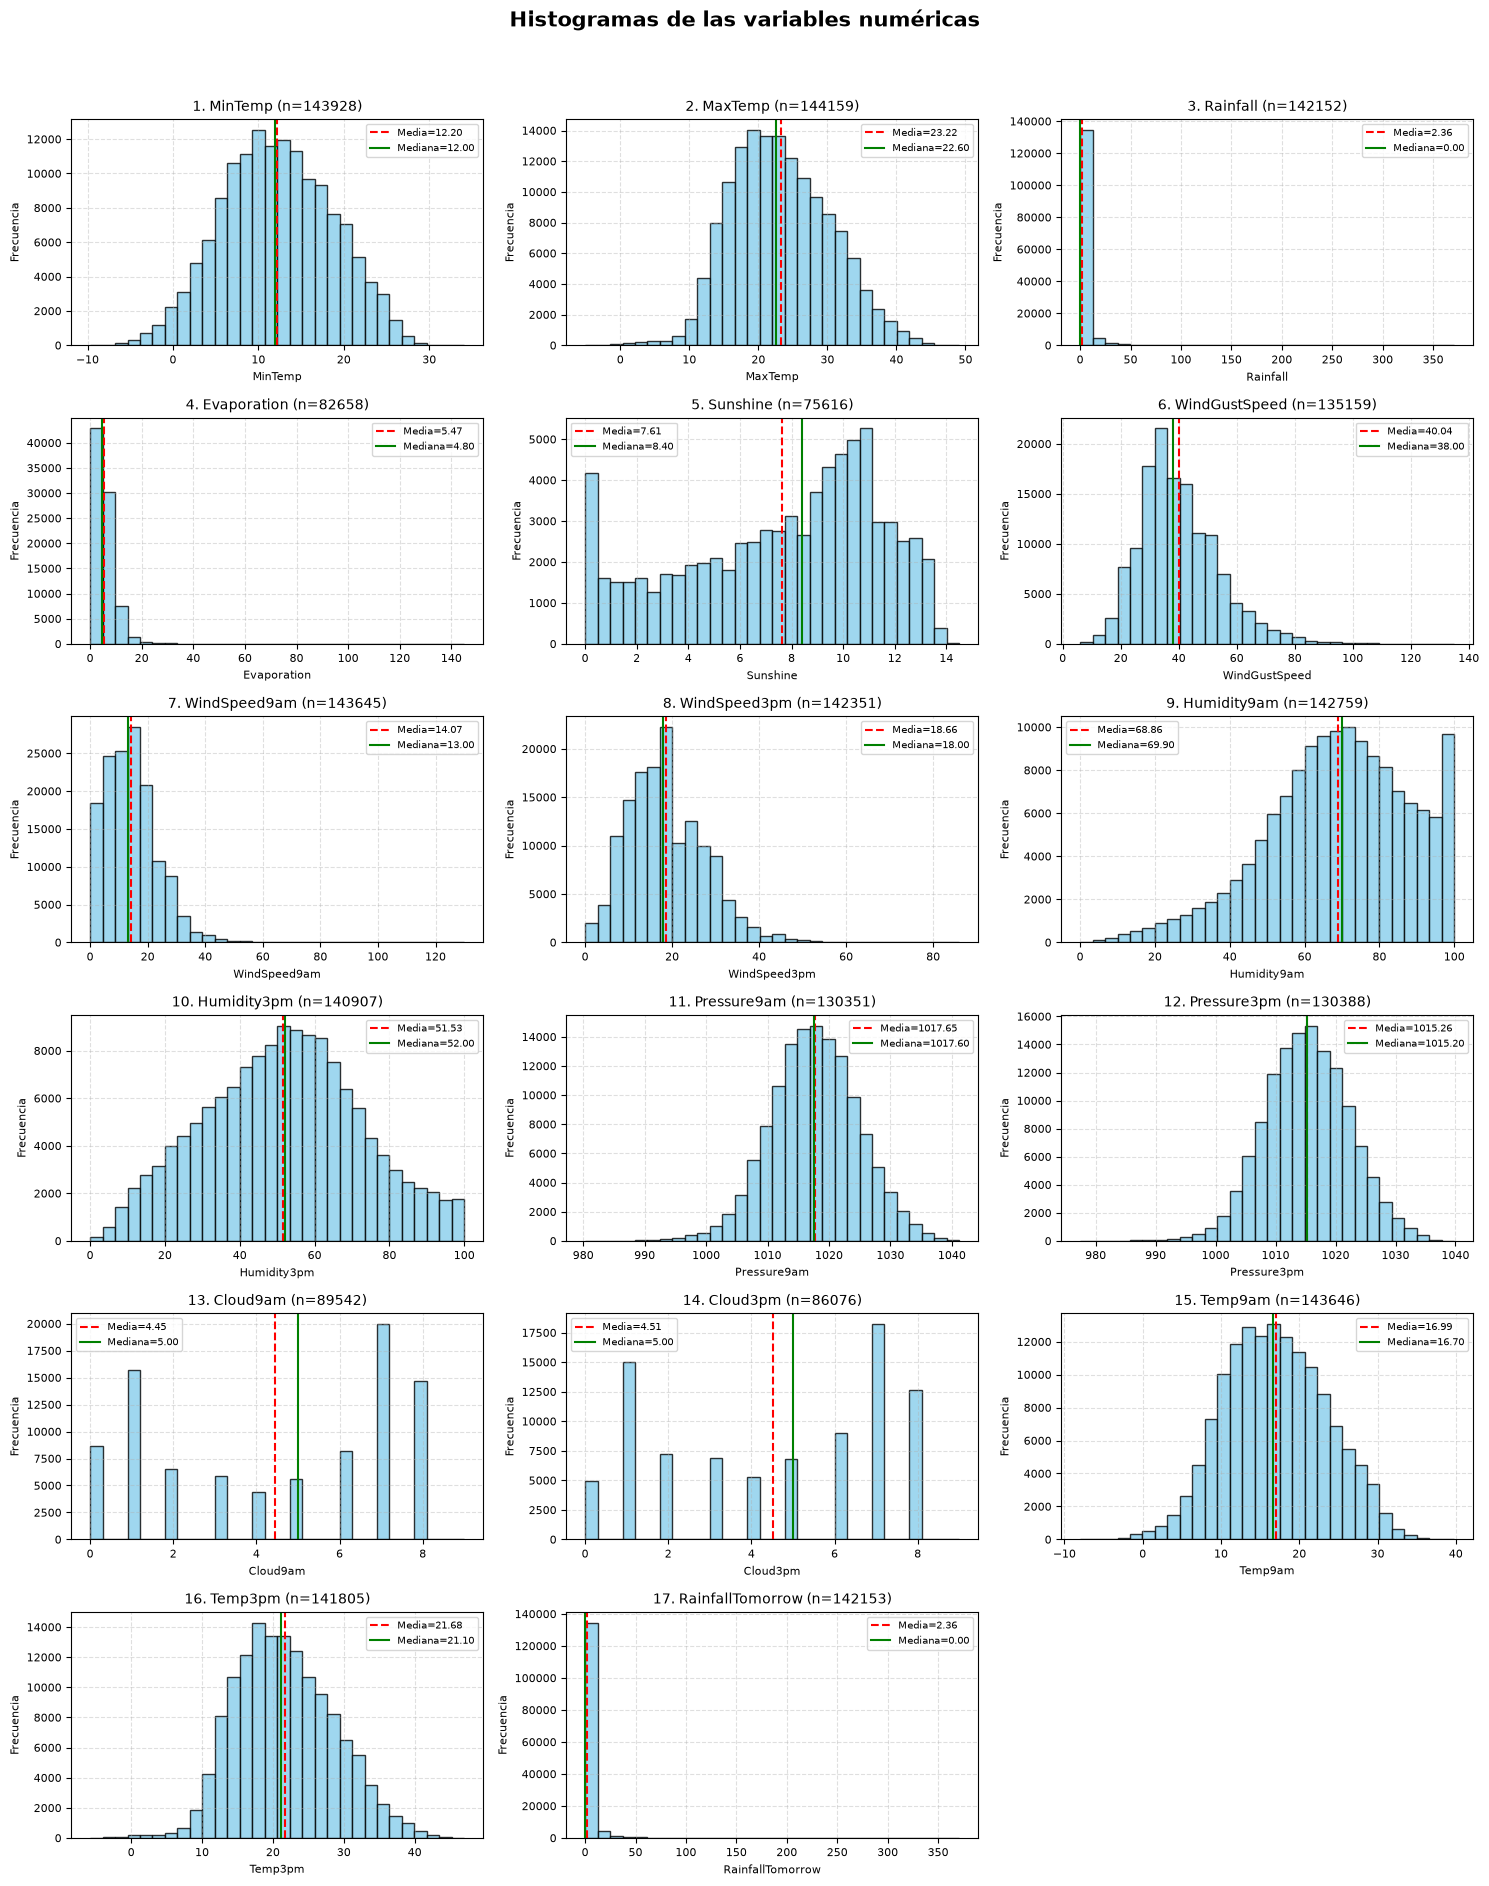

In [14]:

import matplotlib.pyplot as plt

# Variables numéricas del dataset
variables_numericas = df.select_dtypes(include='number').columns

n_vars = len(variables_numericas)
n_cols = 3
n_filas = math.ceil(n_vars / n_cols)

fig, axes = plt.subplots(n_filas, n_cols, figsize=(15, 3.2 * n_filas))
fig.suptitle('Histogramas de las variables numéricas', fontsize=15, fontweight='bold')
axes = axes.flatten()

for i, col in enumerate(variables_numericas):
    datos = df[col].dropna()
    ax = axes[i]

    ax.hist(datos, bins=30, color='skyblue', edgecolor='black', alpha=0.8)
    ax.axvline(datos.mean(), color='red', linestyle='--', linewidth=1.5,
               label=f'Media={datos.mean():.2f}')
    ax.axvline(datos.median(), color='green', linestyle='-', linewidth=1.5,
               label=f'Mediana={datos.median():.2f}')

    ax.set_title(f'{i + 1}. {col} (n={len(datos)})', fontsize=10)
    ax.set_xlabel(col, fontsize=8)
    ax.set_ylabel('Frecuencia', fontsize=8)
    ax.tick_params(labelsize=8)
    ax.grid(linestyle='--', alpha=0.4)
    ax.legend(fontsize=7)

# Ocultar ejes sobrantes si la grilla tiene más lugares que variables
for j in range(n_vars, len(axes)):
    axes[j].axis('off')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()



### Limpieza

##### 1. Unnamed: 0

La primer columna, 'Unnamed: 0', representa el índice del dataset. Pero al examinarla detalladamente notamos que hay valores erroneos dentro de ella (no consecutivos, salteo, etc).
Existen 2 opciones: eliminarla y crearla nuevamente para que se respete el orden de las filas; o bien eliminarla definitivamente. SAeguiremos esta segunda opcion, ya que para el analisis posterior no será necesaria esta información.

In [7]:
df.drop(columns="Unnamed: 0", inplace=True)

df.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,W,...,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,NNW,...,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,W,...,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,SE,...,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,ENE,...,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2
